# LAB 06 — Attention Mechanism

Chạy các cell theo thứ tự. Các hàm dùng chung được import từ `attention_numpy.py`. Những đầu vào W6.pdf không cung cấp được ghi nhãn là dữ liệu giả lập minh họa; chúng không phải kết quả của model đã huấn luyện.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from pathlib import Path
from attention_numpy import (
    softmax_stable, dot_product_attention, scaled_dot_product_attention,
    save_rows_csv, plot_token_attention, plot_attention_matrix,
)
OUTPUT_DIR = Path('.')
csv_rows = []
print('Đã nạp thư viện attention_numpy và sẵn sàng chạy các phần thực hành.')


Đã nạp thư viện attention_numpy và sẵn sàng chạy các phần thực hành.


## 0. Phần 16 - Core implementation

In [16]:
# Ví dụ số nhỏ để minh họa hàm scaled dot-product attention.
Q16 = np.array([[1.0, 0.0]])
K16 = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
V16 = np.array([[1.0, 0.0], [0.0, 2.0], [2.0, 1.0]])
scores16, weights16, context16 = scaled_dot_product_attention(Q16, K16, V16)
print('Scores đã scale:\n', scores16)
print('Attention weights:\n', weights16)
print('Context:\n', context16)

Scores đã scale:
 [[0.70710678 0.         0.70710678]]
Attention weights:
 [[0.40111209 0.19777581 0.40111209]]
Context:
 [[1.20333628 0.79666372]]


## 1. Phần 17 - Numerical stability

In [17]:
x17 = np.array([1000.0, 1001.0, 1002.0])
weights17 = softmax_stable(x17)
print('x =', x17)
print('softmax(x) =', weights17)
print('Tổng trọng số =', weights17.sum())

x = [1000. 1001. 1002.]
softmax(x) = [0.09003057 0.24472847 0.66524096]
Tổng trọng số = 0.9999999999999999


**Tại sao phép trừ max(x) không làm thay đổi kết quả softmax?**
> Phép trừ `max(x)` không làm thay đổi kết quả softmax vì ta trừ cùng một giá trị khỏi tất cả phần tử. Khi đó, tử số và mẫu số cùng được nhân với \(e ^ {- max(x)}\), nên hệ số này triệt tiêu khi chia. Phép trừ chỉ giúp tính toán ổn định hơn, tránh số mũ quá lớn. Kết quả softmax là \([0.0900,\ 0.2447,\ 0.6652]\), có tổng xấp xỉ 1.

## 2. Phần 18 - Experiment 1: Attention distribution

,token,score,attention_weight
0,The,0.1,0.078193
1,movie,0.2,0.086417
2,was,0.2,0.086417
3,surprisingly,0.8,0.157461
4,good,1.0,0.192324
5,despite,0.1,0.078193
6,a,0.1,0.078193
7,very,0.2,0.086417
8,slow,0.1,0.078193
9,beginning,0.1,0.078193


Token có weight lớn nhất: good
Tổng attention weights: 0.9999999999999999


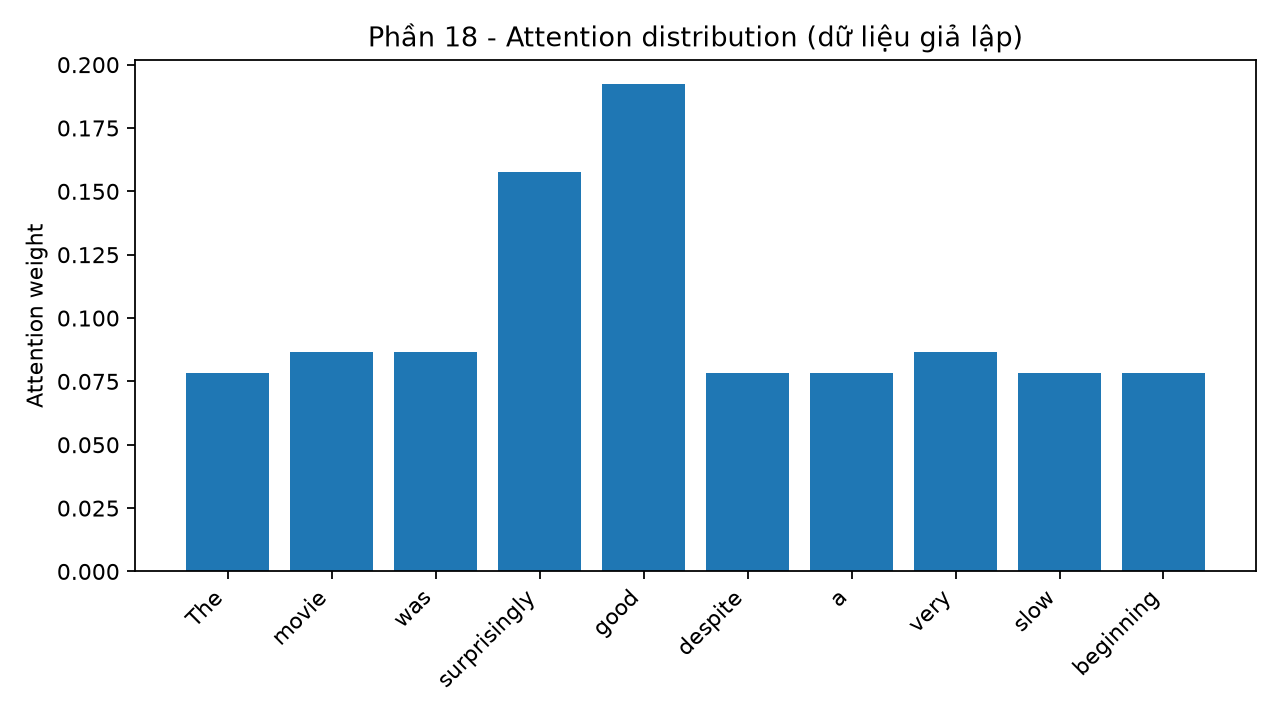

Đã lưu attention_distribution.png


In [18]:
sentence18 = 'The movie was surprisingly good despite a very slow beginning.'
tokens18 = sentence18.replace('.', '').split()
# Dữ liệu giả lập minh họa; PDF không cung cấp query/key/value hay embedding.
keys18 = np.array([
    [0.2,0.1,0.8], [0.9,0.2,0.1], [0.1,0.2,0.1], [0.2,0.8,0.2],
    [0.1,1.0,0.1], [0.3,0.1,0.2], [0.1,0.1,0.1], [0.1,0.2,0.2],
    [0.2,0.1,0.9], [0.4,0.1,0.8],
])
values18 = keys18.copy()
query18 = np.array([0.0, 1.0, 0.0])
scores18, weights18, context18 = dot_product_attention(query18, keys18, values18)
table18 = pd.DataFrame({'token':tokens18,'score':scores18,'attention_weight':weights18})
display(table18)
print('Token có weight lớn nhất:', tokens18[int(np.argmax(weights18))])
print('Tổng attention weights:', weights18.sum())
image18 = OUTPUT_DIR/'attention_distribution.png'
plot_token_attention(tokens18, weights18, 'Phần 18 - Attention distribution (dữ liệu giả lập)', image18)
display(Image(filename=str(image18)))
csv_rows.extend([{'section':'18_attention_distribution','sentence':sentence18,'token':t,'score':float(s),'attention_weight':float(w)} for t,s,w in zip(tokens18,scores18,weights18)])
print('Đã lưu attention_distribution.png')


**Model đang phân phối trọng số như thế nào?**
> Trọng số attention được phân bố không đồng đều giữa các token. Token “good” nhận trọng số cao nhất (0,1923), tiếp theo là “surprisingly” (0,1575). Các token còn lại nhận trọng số thấp hơn, khoảng 0,0782–0,0864. Tổng các trọng số xấp xỉ 1.

## 3. Phần 19 - Experiment 2: Query thay đổi

,token,score_sentiment,weight_sentiment,score_topic,weight_topic
0,The,0.1,0.078193,0.2,0.091244
1,movie,0.2,0.086417,0.9,0.183742
2,was,0.2,0.086417,0.1,0.082561
3,surprisingly,0.8,0.157461,0.2,0.091244
4,good,1.0,0.192324,0.1,0.082561
5,despite,0.1,0.078193,0.3,0.100840
6,a,0.1,0.078193,0.1,0.082561
7,very,0.2,0.086417,0.1,0.082561
8,slow,0.1,0.078193,0.2,0.091244
9,beginning,0.1,0.078193,0.4,0.111445


Phân phối có thay đổi không? Có


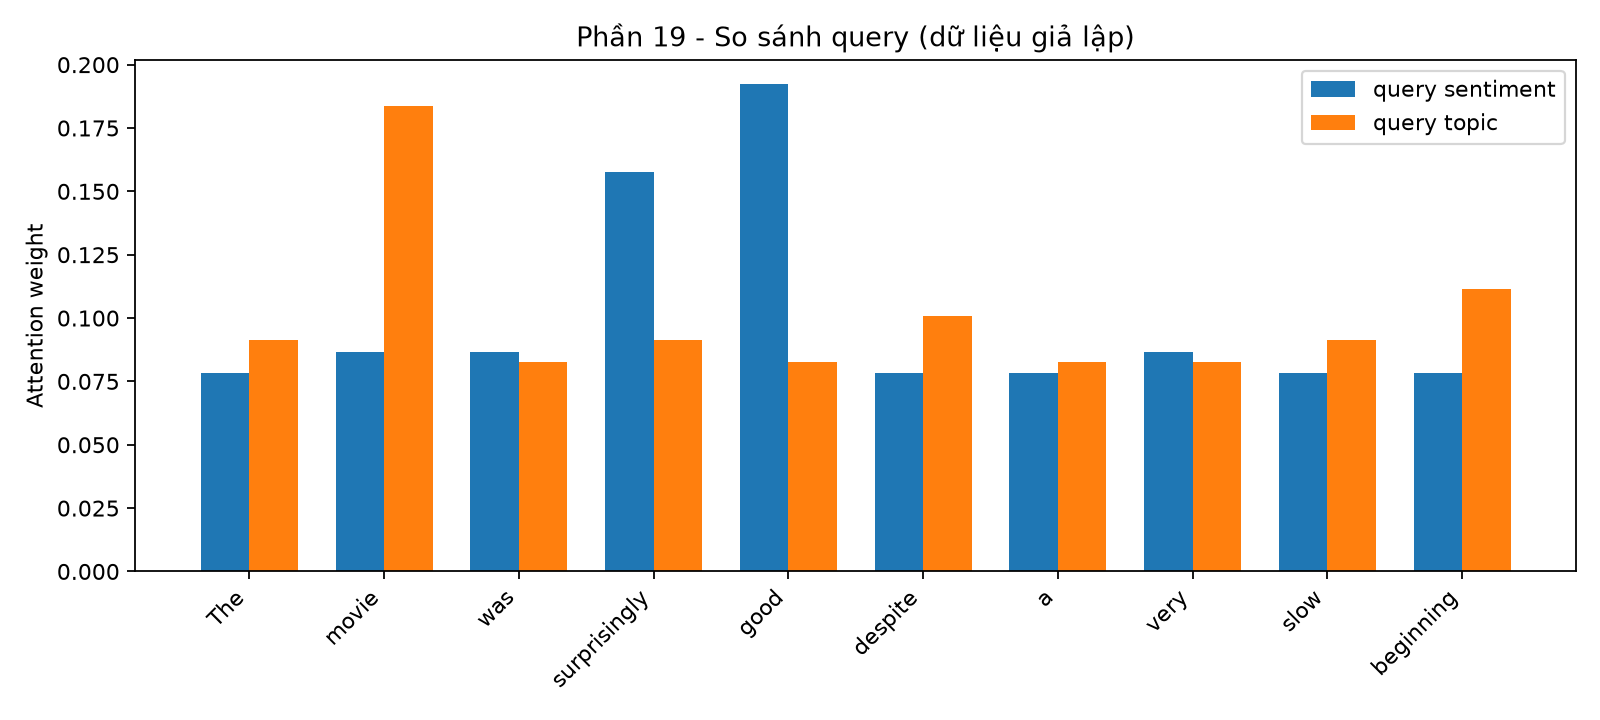

Đã lưu query_comparison.png


In [19]:
# Giữ cùng sequence, keys và values; chỉ thay hai query giả lập.
query_sentiment19 = np.array([0.0, 1.0, 0.0])
query_topic19 = np.array([1.0, 0.0, 0.0])
score_sent19, weight_sent19, _ = dot_product_attention(query_sentiment19, keys18, values18)
score_topic19, weight_topic19, _ = dot_product_attention(query_topic19, keys18, values18)
table19 = pd.DataFrame({'token':tokens18,'score_sentiment':score_sent19,'weight_sentiment':weight_sent19,
                        'score_topic':score_topic19,'weight_topic':weight_topic19})
display(table19)
print('Phân phối có thay đổi không?', 'Có' if not np.allclose(weight_sent19, weight_topic19) else 'Không')
for query_name, scores, weights in [('sentiment',score_sent19,weight_sent19),('topic',score_topic19,weight_topic19)]:
    csv_rows.extend([{'section':'19_query_comparison','sentence':sentence18,'query':query_name,'token':t,
                      'score':float(s),'attention_weight':float(w)} for t,s,w in zip(tokens18,scores,weights)])
xidx = np.arange(len(tokens18))
fig, ax = plt.subplots(figsize=(10,4.5))
ax.bar(xidx-0.18, weight_sent19, 0.36, label='query sentiment')
ax.bar(xidx+0.18, weight_topic19, 0.36, label='query topic')
ax.set_xticks(xidx, tokens18, rotation=45, ha='right')
ax.set_ylabel('Attention weight'); ax.set_title('Phần 19 - So sánh query (dữ liệu giả lập)'); ax.legend()
fig.tight_layout()
image19 = OUTPUT_DIR/'query_comparison.png'
fig.savefig(image19, dpi=160); plt.close(fig)
display(Image(filename=str(image19)))
print('Đã lưu query_comparison.png')


## 4. Phần 21 - Bài tập self-attention

In [20]:
tokens21 = ['I', 'like', 'cats']
# Ví dụ minh họa do notebook chọn vì PDF không ghi các ma trận cụ thể.
X21 = np.array([[1.,0.],[0.,1.],[1.,1.]])
WQ21 = np.eye(2); WK21 = np.eye(2); WV21 = np.eye(2)
Q21 = X21 @ WQ21; K21 = X21 @ WK21; V21 = X21 @ WV21
raw21 = Q21 @ K21.T
scores21, weights21, context21 = scaled_dot_product_attention(Q21,K21,V21)
print('X =\n',X21,'\nWQ =\n',WQ21,'\nWK =\n',WK21,'\nWV =\n',WV21)
print('Q =\n',Q21,'\nK =\n',K21,'\nV =\n',V21)
print('QK^T =\n',raw21)
print('Scaled scores =\n',scores21)
print('Attention weights =\n',weights21)
print('Context =\n',context21)

X =
 [[1. 0.]
 [0. 1.]
 [1. 1.]] 
WQ =
 [[1. 0.]
 [0. 1.]] 
WK =
 [[1. 0.]
 [0. 1.]] 
WV =
 [[1. 0.]
 [0. 1.]]
Q =
 [[1. 0.]
 [0. 1.]
 [1. 1.]] 
K =
 [[1. 0.]
 [0. 1.]
 [1. 1.]] 
V =
 [[1. 0.]
 [0. 1.]
 [1. 1.]]
QK^T =
 [[1. 0. 1.]
 [0. 1. 1.]
 [1. 1. 2.]]
Scaled scores =
 [[0.70710678 0.         0.70710678]
 [0.         0.70710678 0.70710678]
 [0.70710678 0.70710678 1.41421356]]
Attention weights =
 [[0.40111209 0.19777581 0.40111209]
 [0.19777581 0.40111209 0.40111209]
 [0.24825508 0.24825508 0.50348984]]
Context =
 [[0.80222419 0.59888791]
 [0.59888791 0.80222419]
 [0.75174492 0.75174492]]


## 5. Phần 22 - Attention matrix

,I,like,cats
I,0.401112,0.197776,0.401112
like,0.197776,0.401112,0.401112
cats,0.248255,0.248255,0.503490


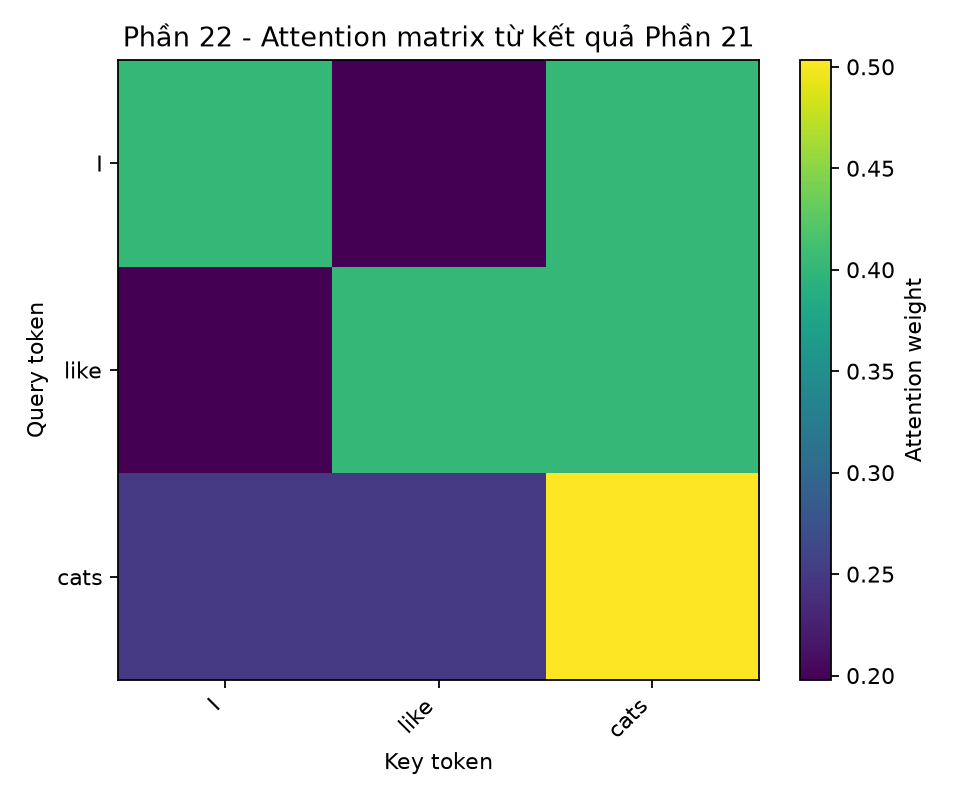

Đã lưu heatmap attention_matrix.png


In [21]:
tokens22 = ['I', 'like', 'cats']

# Dùng attention weights vừa tính ở Phần 21
attention22 = weights21

display(pd.DataFrame(attention22, index=tokens22, columns=tokens22))

plot_attention_matrix(
    tokens22,
    attention22,
    'Phần 22 - Attention matrix từ kết quả Phần 21',
    OUTPUT_DIR / 'attention_matrix.png'
)

display(Image(filename=str(OUTPUT_DIR / 'attention_matrix.png')))
print('Đã lưu heatmap attention_matrix.png')

## 6. Phần 23 - Experiment 3: Attention visualization

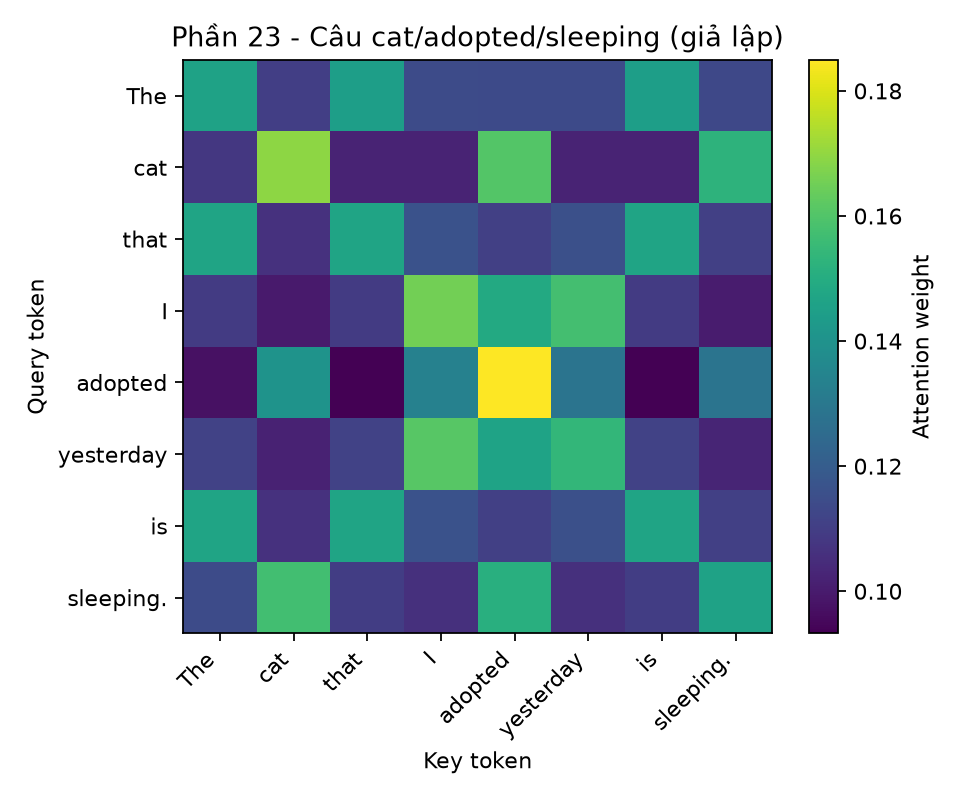

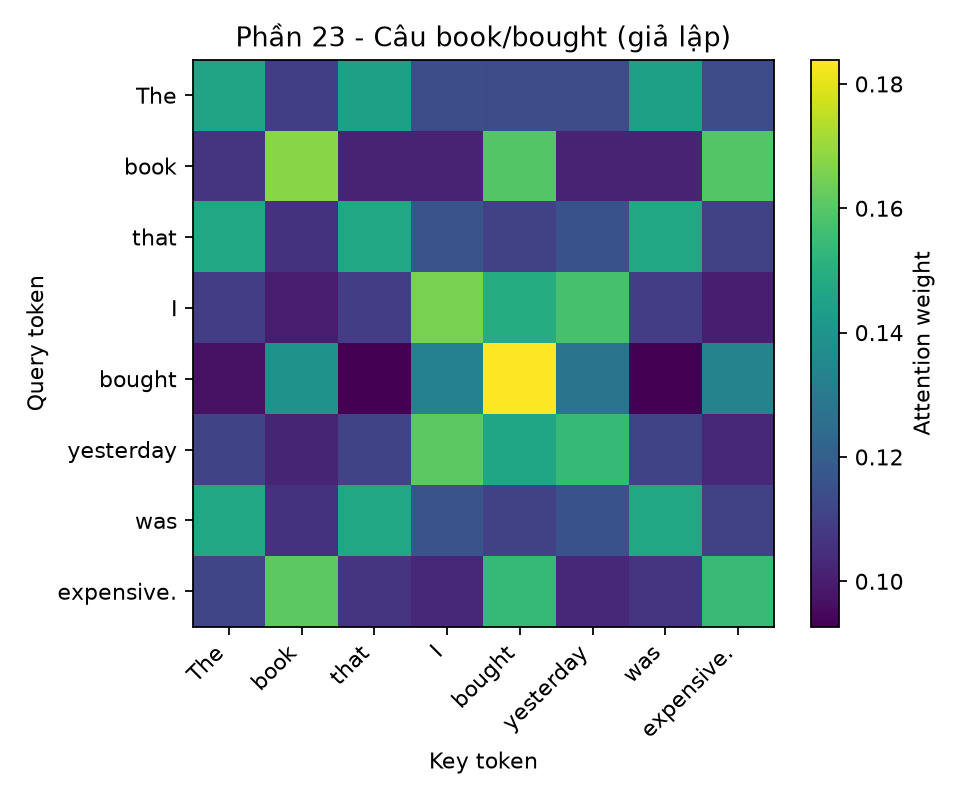

Phân phối của query token: cat


,key_token,attention_weight
0,cat,0.169536
1,adopted,0.160463
2,sleeping.,0.152637
3,The,0.108101
4,yesterday,0.102316
5,is,0.102316
6,that,0.102316
7,I,0.102316


Phân phối của query token: adopted


,key_token,attention_weight
0,adopted,0.184981
1,cat,0.140506
2,I,0.133654
3,sleeping.,0.128413
4,yesterday,0.128413
5,The,0.097539
6,is,0.093247
7,that,0.093247


Phân phối của query token: sleeping.


,key_token,attention_weight
0,cat,0.157297
1,adopted,0.151129
2,sleeping.,0.145931
3,The,0.114221
4,that,0.109742
5,is,0.109742
6,yesterday,0.105968
7,I,0.105968


Đã lưu hai heatmap riêng cho hai câu.


In [22]:
tokens23a = ['The','cat','that','I','adopted','yesterday','is','sleeping.']
tokens23b = ['The','book','that','I','bought','yesterday','was','expensive.']
# Vector giả lập theo quy tắc minh họa; không phải embedding/model đã huấn luyện.
vectors23 = {
 'The':[0.1,0.1,0.1,0.8], 'cat':[1.0,0.1,0.0,0.0], 'book':[0.0,1.0,0.0,0.0],
 'that':[0.0,0.0,0.1,0.8], 'I':[0.0,0.0,1.0,0.1], 'adopted':[0.9,0.0,0.8,0.0],
 'bought':[0.0,0.9,0.8,0.0], 'yesterday':[0.0,0.0,0.9,0.1], 'is':[0.0,0.0,0.1,0.8],
 'was':[0.0,0.0,0.1,0.8], 'sleeping.':[0.8,0.0,0.0,0.1], 'expensive.':[0.0,0.9,0.0,0.1]
}
def make_simulated_self_attention(tokens):
    X = np.array([vectors23[token] for token in tokens], dtype=float)
    scores, weights, context = scaled_dot_product_attention(X,X,X)
    return X, scores, weights, context
X23a,scores23a,weights23a,context23a=make_simulated_self_attention(tokens23a)
X23b,scores23b,weights23b,context23b=make_simulated_self_attention(tokens23b)
image23a=OUTPUT_DIR/'attention_sentence_cat.png'
image23b=OUTPUT_DIR/'attention_sentence_book.png'
plot_attention_matrix(tokens23a,weights23a,'Phần 23 - Câu cat/adopted/sleeping (giả lập)',image23a)
plot_attention_matrix(tokens23b,weights23b,'Phần 23 - Câu book/bought (giả lập)',image23b)
display(Image(filename=str(image23a)))
display(Image(filename=str(image23b)))
def show_query_row(tokens, matrix, token):
    row=matrix[tokens.index(token)]
    order=np.argsort(row)[::-1]
    display(pd.DataFrame({'key_token':[tokens[i] for i in order],'attention_weight':row[order]}))
for token in ['cat','adopted','sleeping.']:
    print('Phân phối của query token:',token)
    show_query_row(tokens23a,weights23a,token)
    row=weights23a[tokens23a.index(token)]
    csv_rows.extend([{'section':'23_attention_visualization','sentence':'The cat that I adopted yesterday is sleeping.',
                      'query_token':token,'key_token':key,'attention_weight':float(weight)}
                     for key,weight in zip(tokens23a,row)])
print('Đã lưu hai heatmap riêng cho hai câu.')


> **Nhận xét pattern:** Dựa vào ba bảng ngay phía trên, ghi token/key nào nhận trọng số cao của `cat`, `adopted` và `sleeping`. Đây là attention pattern từ vector giả lập theo quy tắc minh họa; heatmap tự nó không chứng minh model hiểu ngữ pháp, reasoning hay quan hệ ngôn ngữ.

## 7. Phần 24 - Experiment 4: RNN context vs Attention context

In [23]:
# Dùng lại chính dataset, split, padding và test set trong LAB 05.
import random
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from attention_numpy import build_attention_classifier, train_evaluate_attention_classifier

SEED24 = 42
VOCAB_SIZE24 = 20_000
EMBEDDING_DIM24 = 64
MAX_LENGTH24 = 200
BATCH_SIZE24 = 128
EPOCHS24 = 5

random.seed(SEED24)
np.random.seed(SEED24)
tf.keras.utils.set_random_seed(SEED24)

(train_sequences24, y_train_full24), (test_sequences24, y_test24) = imdb.load_data(
    num_words=VOCAB_SIZE24
)
X_train_seq24, X_val_seq24, y_train24, y_val24 = train_test_split(
    train_sequences24,
    y_train_full24,
    test_size=0.2,
    random_state=SEED24,
    stratify=y_train_full24,
)

def pad_sequences24(sequences):
    return pad_sequences(
        sequences, maxlen=MAX_LENGTH24,
        padding='post', truncating='post', value=0
    )

X_train24 = pad_sequences24(X_train_seq24)
X_val24 = pad_sequences24(X_val_seq24)
X_test24 = pad_sequences24(test_sequences24)
y_train24 = np.asarray(y_train24, dtype='float32')
y_val24 = np.asarray(y_val24, dtype='float32')
y_test24 = np.asarray(y_test24, dtype='int32')

attention_model24, attention_weights_model24 = build_attention_classifier(
    vocab_size=VOCAB_SIZE24,
    embedding_dim=EMBEDDING_DIM24,
    max_length=MAX_LENGTH24,
    dropout_rate=0.3,
    learning_rate=1e-3,
)
attention_result24 = train_evaluate_attention_classifier(
    attention_model24,
    X_train24, y_train24,
    X_val24, y_val24,
    X_test24, y_test24,
    batch_size=BATCH_SIZE24,
    epochs=EPOCHS24,
    seed=SEED24,
    verbose=1,
)

print(f"LAB 06 Accuracy: {attention_result24['accuracy']:.4f}")
print(f"LAB 06 F1 (binary): {attention_result24['f1']:.4f}")
print(f"LAB 06 Training time: {attention_result24['training_time_seconds']:.2f} giây")
print(f"LAB 06 Parameters: {attention_result24['parameters']:,}")

# Đọc chỉ số LSTM đã lưu ở LAB 05; nếu thiếu thì để trống để nhập thủ công.
lab05_results_path24 = Path(r'C:\Users\ADMIN\NLP_Apps_Labs\lab05\results.csv')
lab05_lstm24 = None
if lab05_results_path24.exists():
    lab05_results24 = pd.read_csv(lab05_results_path24)
    if 'model' in lab05_results24.columns:
        matched24 = lab05_results24[
            lab05_results24['model'].astype(str).str.strip().str.casefold() == 'lstm'
        ]
        if not matched24.empty:
            lab05_lstm24 = matched24.iloc[0]

if lab05_lstm24 is None:
    print('Chưa tìm thấy dòng LSTM trong lab05/results.csv; nhập số liệu LAB 05 thủ công nếu cần.')
    lab05_accuracy24 = ''
    lab05_f124 = ''
    lab05_time24 = ''
    lab05_params24 = ''
else:
    lab05_accuracy24 = lab05_lstm24.get('accuracy', '')
    lab05_f124 = lab05_lstm24.get('f1', '')
    lab05_time24 = lab05_lstm24.get('training_time_seconds', '')
    lab05_params24 = lab05_lstm24.get('parameters', '')

comparison24 = pd.DataFrame([
    {
        'model':'LAB 05 LSTM', 'accuracy':lab05_accuracy24,
        'f1':lab05_f124, 'f1_type':'binary',
        'training_time_seconds':lab05_time24, 'parameters':lab05_params24,
    },
    {
        'model':'LAB 06 Self-Attention', 'accuracy':attention_result24['accuracy'],
        'f1':attention_result24['f1'], 'f1_type':'binary',
        'training_time_seconds':attention_result24['training_time_seconds'],
        'parameters':attention_result24['parameters'],
    },
])
display(comparison24)

# Thêm các dòng vào danh sách đang được xuất ở cell CSV cuối notebook.
csv_rows.extend([
    {'section':'24_model_comparison', **row}
    for row in comparison24.to_dict(orient='records')
])


Epoch 1/5


C:\Users\ADMIN\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\layer.py:1039: UserWarning: Layer 'masked_mean_pooling' (of type MaskedMeanPooling) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - accuracy: 0.7596 - loss: 0.5051 - val_accuracy: 0.8492 - val_loss: 0.3439
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.8952 - loss: 0.2633 - val_accuracy: 0.8666 - val_loss: 0.3198
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 11s 68ms/step - accuracy: 0.9315 - loss: 0.1825 - val_accuracy: 0.8680 - val_loss: 0.3475
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 33s 147ms/step - accuracy: 0.9579 - loss: 0.1213 - val_accuracy: 0.8606 - val_loss: 0.4204
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 25s 157ms/step - accuracy: 0.9778 - loss: 0.0746 - val_accuracy: 0.8528 - val_loss: 0.5340
LAB 06 Accuracy: 0.8354
LAB 06 F1 (binary): 0.8296
LAB 06 Training time: 81.34 giây
LAB 06 Parameters: 1,292,353


,model,accuracy,f1,f1_type,training_time_seconds,parameters
0,LAB 05 LSTM,0.79616,0.808118,binary,70.921714,1313089
1,LAB 06 Self-Attention,0.83536,0.829622,binary,81.342842,1292353


**Representation của hai model khác nhau ở đâu?**
> LSTM biểu diễn toàn bộ chuỗi bằng hidden state cuối cùng, được cập nhật lần lượt khi đọc các token. Self-Attention tạo biểu diễn theo ngữ cảnh cho từng token bằng cách cho các token chú ý trực tiếp đến nhau, rồi kết hợp các biểu diễn đó thành context để phân loại.

## 8. Phần 25 - Experiment 5: Sequence length và computational cost

In [24]:
lengths25=[10,100,500,1000]
table25=pd.DataFrame({'T':lengths25,'attention_matrix':[f'{t} × {t}' for t in lengths25],
                       'matrix_elements':[t*t for t in lengths25]})
display(table25)
csv_rows.extend([{'section':'25_sequence_cost','T':int(t),'attention_matrix':f'{t} × {t}',
                  'matrix_elements':int(t*t)} for t in lengths25])


,T,attention_matrix,matrix_elements
0,10,10 × 10,100
1,100,100 × 100,10000
2,500,500 × 500,250000
3,1000,1000 × 1000,1000000


**Tại sao self-attention có vấn đề computational cost khi sequence rất dài?**
> Ma trận có `T×T` phần tử nên chi phí tính toán và bộ nhớ tăng theo `O(T²)`. Khi độ dài chuỗi tăng, số cặp token tăng bình phương.

## 9. Phần 26 - Application: Context-aware sentiment

Câu 1: I like this movie.
Dự đoán: positive
Xác suất positive: 0.8793


,token,attention_weight
0,<START>,0.207050
1,i,0.204840
2,like,0.191736
3,this,0.197719
4,movie,0.198656


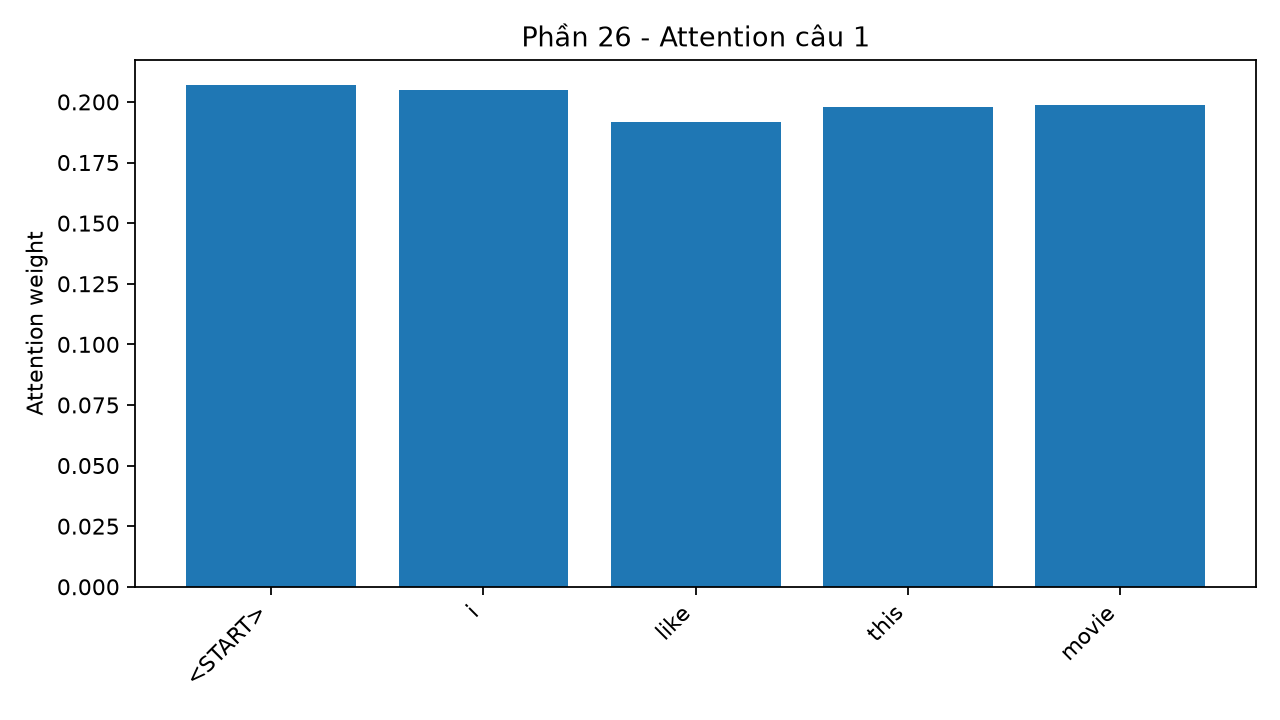

Câu 2: I do not like this movie.
Dự đoán: negative
Xác suất positive: 0.3660


,token,attention_weight
0,<START>,0.146379
1,i,0.145422
2,do,0.142527
3,not,0.139634
4,like,0.140407
5,this,0.142600
6,movie,0.143032


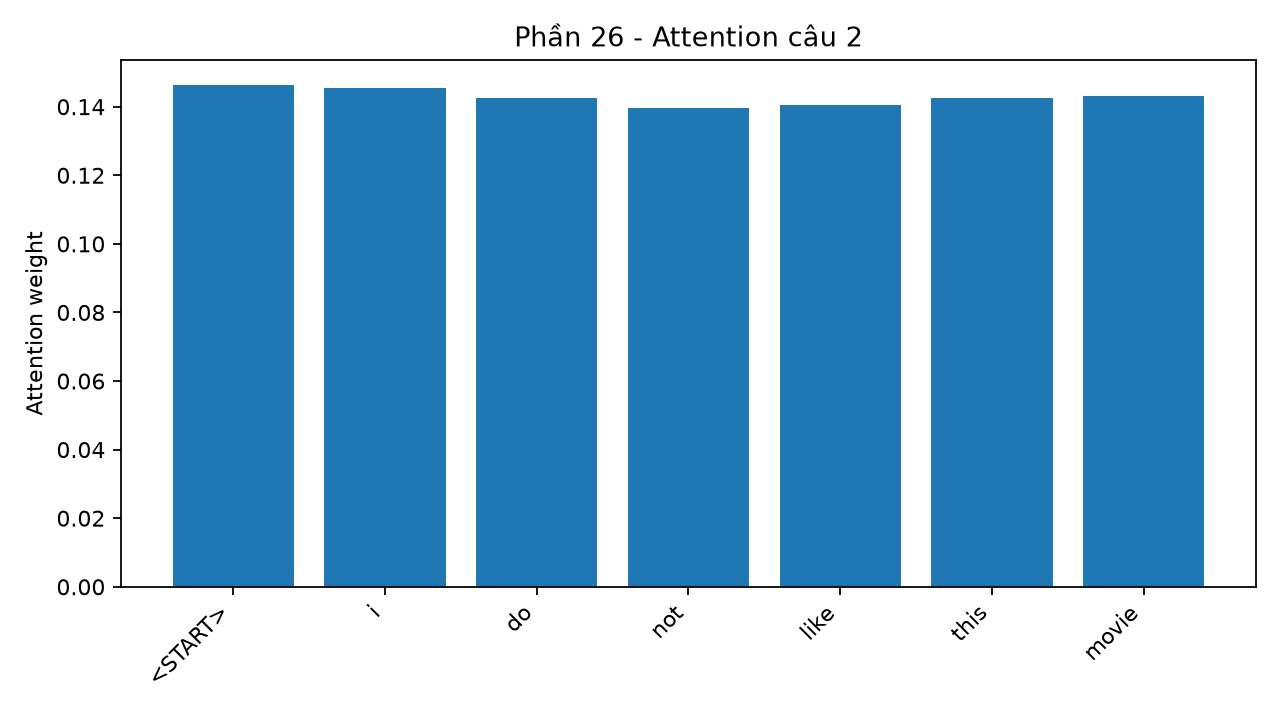

Câu 3: I thought this movie would be bad, but it was actually excellent.
Dự đoán: positive
Xác suất positive: 0.9984


,token,attention_weight
0,<START>,0.059843
1,i,0.059297
2,thought,0.063462
3,this,0.057984
4,movie,0.058107
5,would,0.066385
6,be,0.058248
7,bad,0.140391
8,but,0.057761
9,it,0.059441


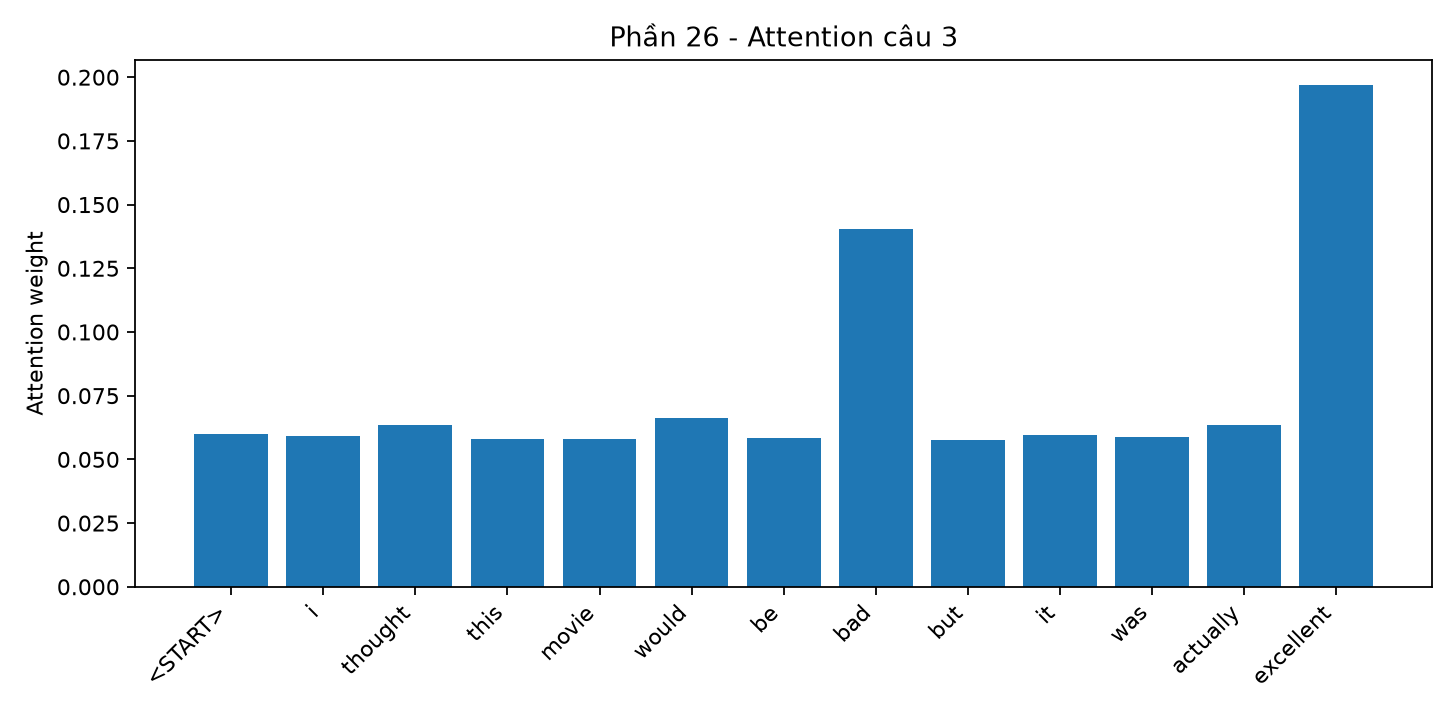

Câu 4: I expected this movie to be awful, but it turned out to be excellent.
Dự đoán: positive
Xác suất positive: 0.9975


,token,attention_weight
0,<START>,0.054924
1,i,0.054338
2,expected,0.066594
3,this,0.052523
4,movie,0.052731
5,to,0.052600
6,be,0.050523
7,awful,0.117950
8,but,0.051284
9,it,0.054529


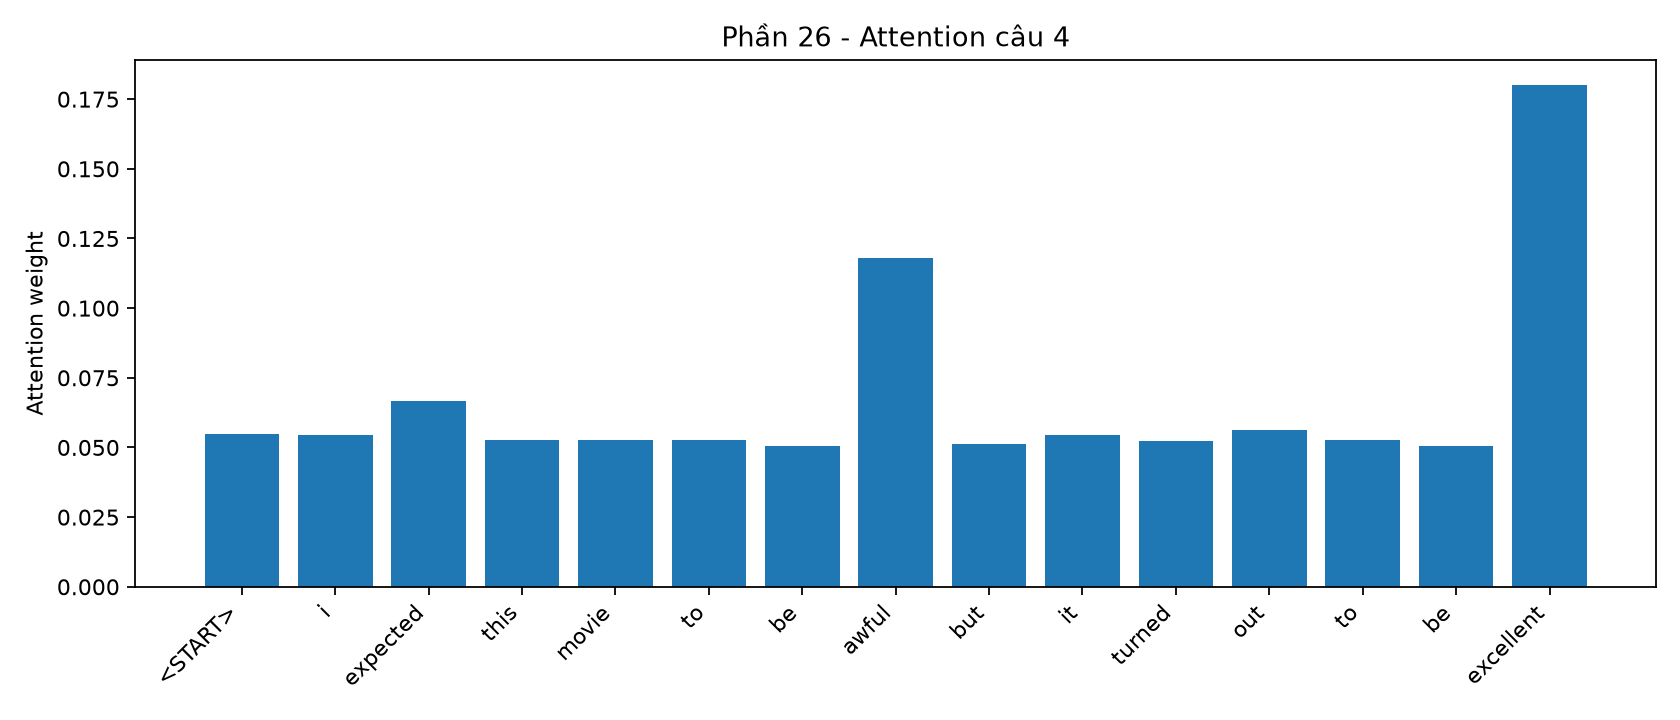

Câu 5: What a brilliant movie: the plot was incoherent, the acting was lifeless, and I couldn't wait for it to end.
Dự đoán: negative
Xác suất positive: 0.0000


,token,attention_weight
0,<START>,0.034886
1,what,0.038170
2,a,0.033029
3,brilliant,0.093989
4,movie,0.033628
5,the,0.033246
6,plot,0.033210
7,was,0.032535
8,incoherent,0.050410
9,the,0.033246


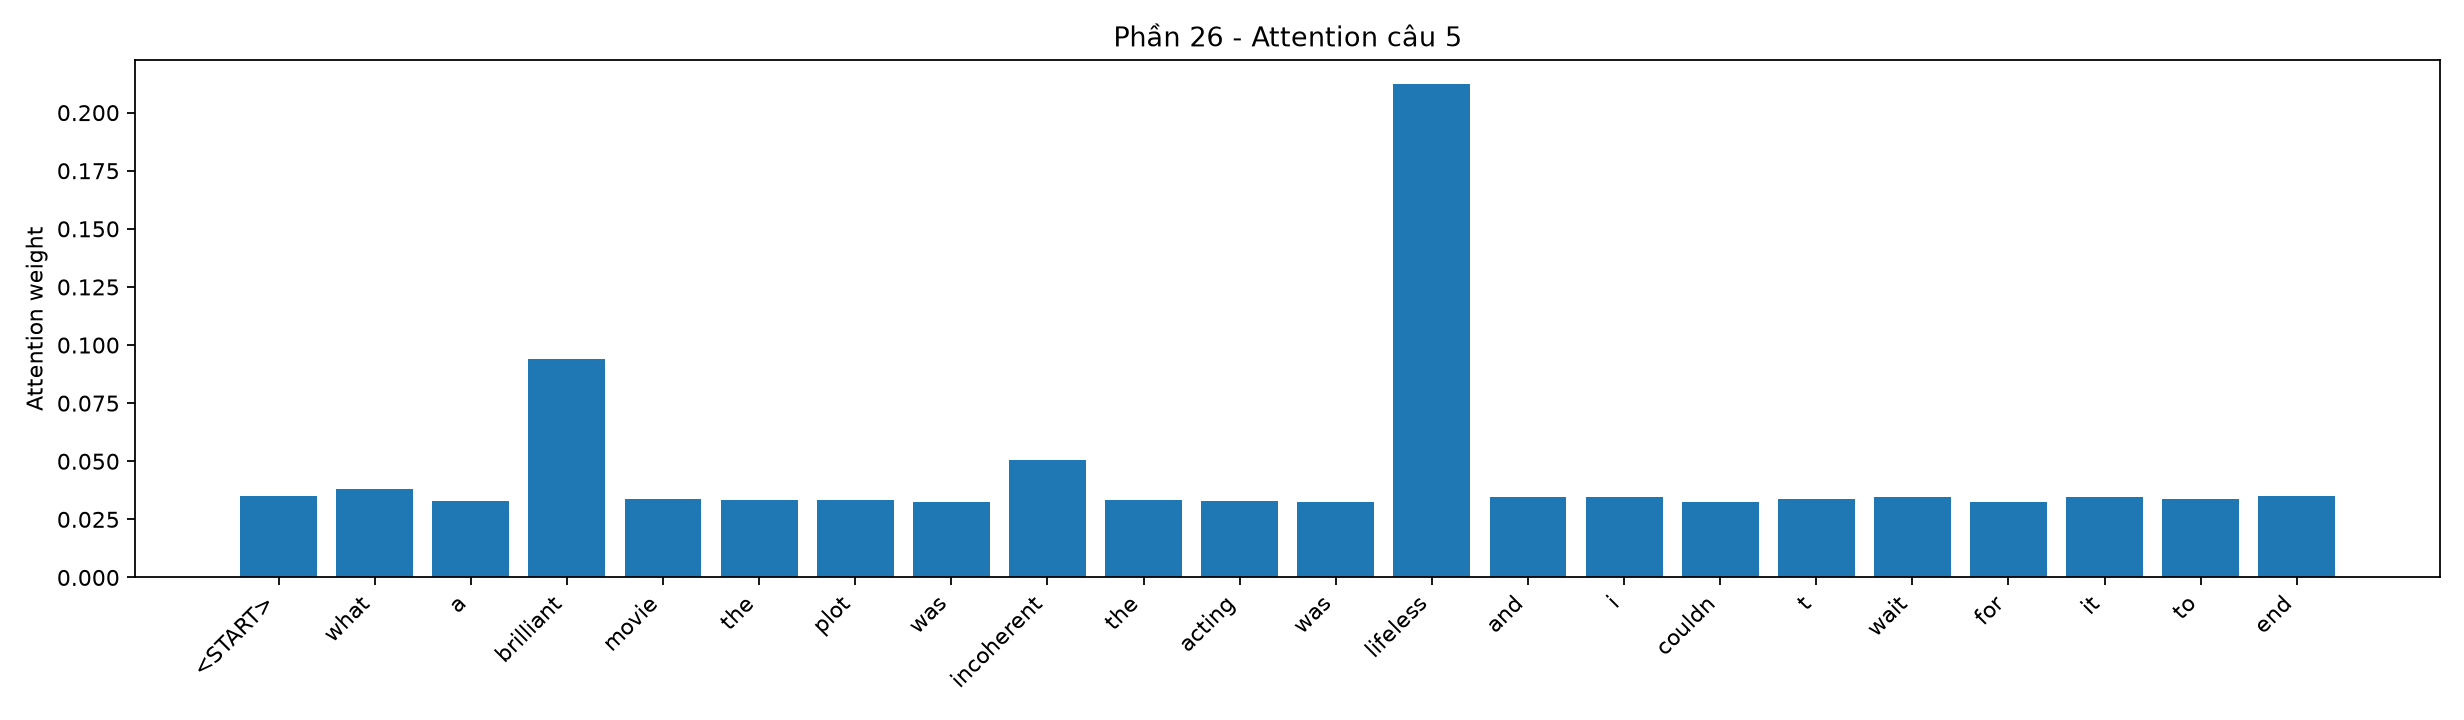

Câu 6: The film was not bad at all; in fact, I enjoyed it more than I expected.
Dự đoán: positive
Xác suất positive: 0.9948


,token,attention_weight
0,<START>,0.052346
1,the,0.048975
2,film,0.051440
3,was,0.047937
4,not,0.048098
5,bad,0.095129
6,at,0.048818
7,all,0.048001
8,in,0.048874
9,fact,0.050595


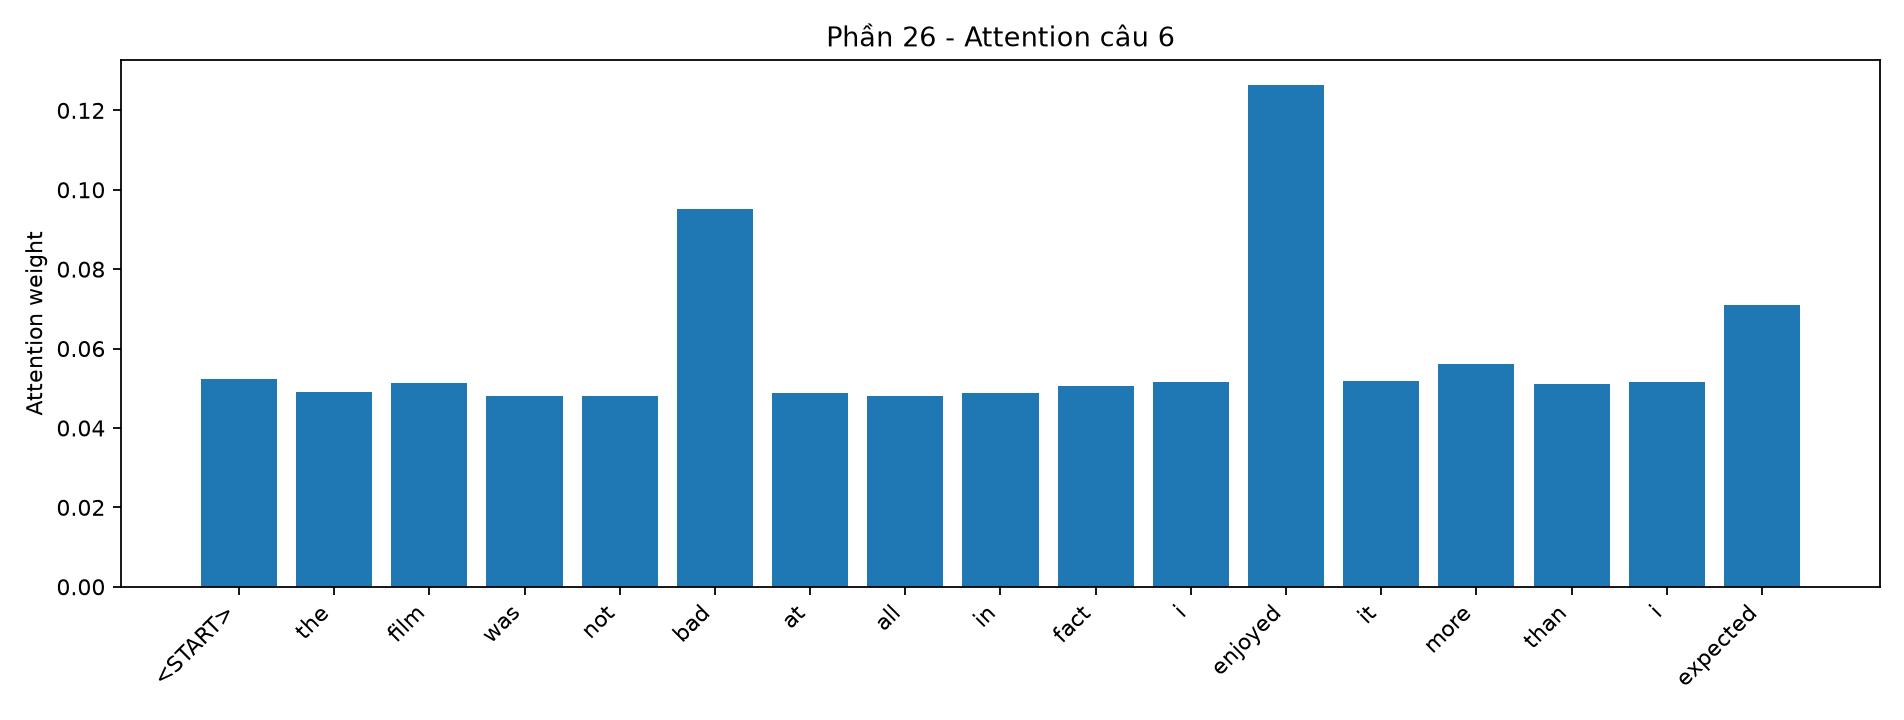

Đã thêm kết quả Phần 26 vào danh sách chờ xuất results.csv.


In [25]:
import re
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

sentences26 = [
    "I like this movie.",
    "I do not like this movie.",
    "I thought this movie would be bad, but it was actually excellent.",
    "I expected this movie to be awful, but it turned out to be excellent.",
    "What a brilliant movie: the plot was incoherent, the acting was lifeless, and I couldn't wait for it to end.",
    "The film was not bad at all; in fact, I enjoyed it more than I expected."
]

# Cần chạy Phần 24 trước để các biến model và cấu hình này tồn tại.
required_variables = [
    "attention_model24",
    "attention_weights_model24",
    "VOCAB_SIZE24",
    "MAX_LENGTH24",
]

missing = [name for name in required_variables if name not in globals()]

if missing:
    print("Chưa có model Attention từ Phần 24. Hãy chạy Phần 24 trước.")
else:
    word_index = imdb.get_word_index()

    def encode_review26(sentence):
        # Keras IMDb dùng chỉ số 1 cho token bắt đầu và 2 cho từ ngoài từ vựng.
        tokens = re.findall(r"[a-z]+", sentence.lower())
        token_ids = [1]  # <START>

        for token in tokens:
            word_id = word_index.get(token)
            token_id = word_id + 3 if word_id is not None else 2

            if token_id >= VOCAB_SIZE24:
                token_id = 2

            token_ids.append(token_id)

        return tokens, token_ids

    result_rows26 = []

    for i, sentence in enumerate(sentences26, start=1):
        tokens, token_ids = encode_review26(sentence)

        # Thêm nhãn <START> để khớp với token ID đầu vào model.
        display_tokens = ["<START>"] + tokens

        padded_ids = pad_sequences(
            [token_ids],
            maxlen=MAX_LENGTH24,
            padding="post",
            truncating="post",
            value=0
        )

        positive_probability = float(
            attention_model24.predict(padded_ids, verbose=0).reshape(-1)[0]
        )
        prediction = (
            "positive" if positive_probability >= 0.5 else "negative"
        )

        # Lấy ma trận attention (1, T, T), bỏ các hàng/cột padding,
        # rồi lấy trung bình theo các query token để có một weight/token.
        attention_matrix = attention_weights_model24.predict(
            padded_ids, verbose=0
        )[0]

        valid_length = min(len(display_tokens), MAX_LENGTH24)
        valid_attention = attention_matrix[:valid_length, :valid_length]
        token_weights = valid_attention.mean(axis=0)

        print(f"Câu {i}: {sentence}")
        print(f"Dự đoán: {prediction}")
        print(f"Xác suất positive: {positive_probability:.4f}")

        display(pd.DataFrame({
            "token": display_tokens[:valid_length],
            "attention_weight": token_weights
        }))

        image_path = OUTPUT_DIR / f"attention_sentiment_{i}.png"
        plot_token_attention(
            display_tokens[:valid_length],
            token_weights,
            f"Phần 26 - Attention câu {i}",
            image_path
        )
        display(Image(filename=str(image_path)))

        result_rows26.extend([
            {
                "section": "26_context_aware_sentiment",
                "sentence": sentence,
                "prediction": prediction,
                "positive_probability": positive_probability,
                "token": token,
                "attention_weight": float(weight)
            }
            for token, weight in zip(
                display_tokens[:valid_length],
                token_weights
            )
        ])

    # Thêm dữ liệu vào danh sách để cell xuất CSV cuối notebook ghi chung.
    if "csv_rows" not in globals():
        csv_rows = []

    csv_rows.extend(result_rows26)
    print("Đã thêm kết quả Phần 26 vào danh sách chờ xuất results.csv.")

In [26]:
# Xuất tất cả kết quả đã tích lũy vào cùng một CSV.
save_rows_csv(OUTPUT_DIR / 'results.csv', csv_rows)


WindowsPath('results.csv')